<a href="https://colab.research.google.com/github/narayan-dnv/MLE-CS3/blob/main/CS_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")


In [2]:
import kagglehub

path = kagglehub.dataset_download("carrie1/ecommerce-data")
print(path)


Using Colab cache for faster access to the 'ecommerce-data' dataset.
/kaggle/input/ecommerce-data


In [3]:
df = pd.read_csv(path + "/data.csv", encoding="ISO-8859-1")
df.shape


(541909, 8)

In [4]:
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
df = df.dropna(subset=['CustomerID'])
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df.shape


(397884, 9)

In [6]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm.head()


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [7]:
rfm.describe()


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


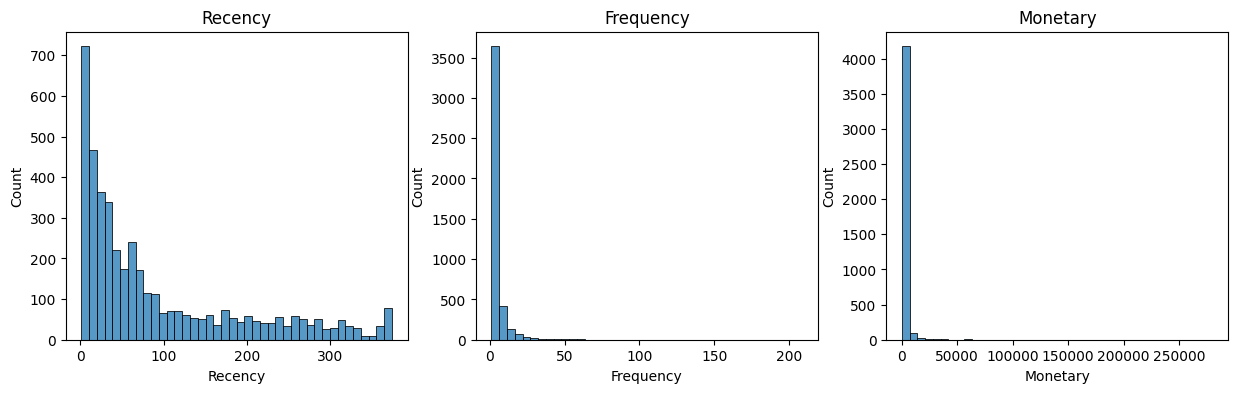

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, rfm.columns):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(col)
plt.show()


In [9]:
rfm_log = np.log1p(rfm)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(rfm_scaled, index=rfm.index, columns=rfm.columns)
rfm_scaled.head()


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,1.461993,-0.955214,3.706225
12347.0,-2.038734,1.074425,1.411843
12348.0,0.373104,0.386304,0.716489
12349.0,-0.623086,-0.955214,0.698739
12350.0,1.424558,-0.955214,-0.618962


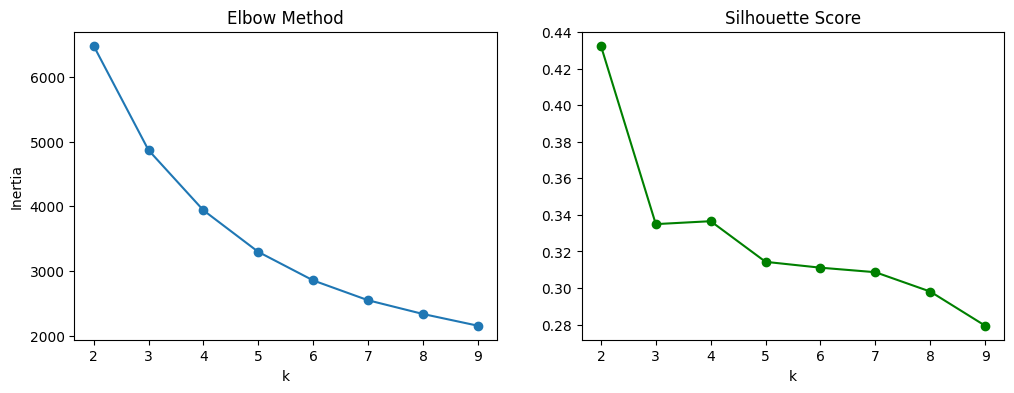

In [10]:
inertias = []
sil_scores = []
K_range = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(rfm_scaled, labels, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, marker='o')
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(K_range, sil_scores, marker='o', color='green')
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k")
plt.show()


In [11]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm['KMeans_Cluster'].value_counts().sort_index()


,count
KMeans_Cluster,
0,837
1,716
2,1173
3,1612


In [12]:
dbscan = DBSCAN(eps=0.5, min_samples=15)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

print("Clusters found:", len(set(rfm['DBSCAN_Cluster'])) - (1 if -1 in rfm['DBSCAN_Cluster'].values else 0))
print("Noise points:", (rfm['DBSCAN_Cluster'] == -1).sum())
rfm['DBSCAN_Cluster'].value_counts().sort_index()


Clusters found: 2
Noise points: 105


,count
DBSCAN_Cluster,
-1,105
0,2762
1,1471


In [13]:
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(rfm_scaled)

rfm['PCA1'] = pca_result[:, 0]
rfm['PCA2'] = pca_result[:, 1]

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())


Explained variance ratio: [0.75102042 0.18759201]
Total variance explained: 0.9386124314129813


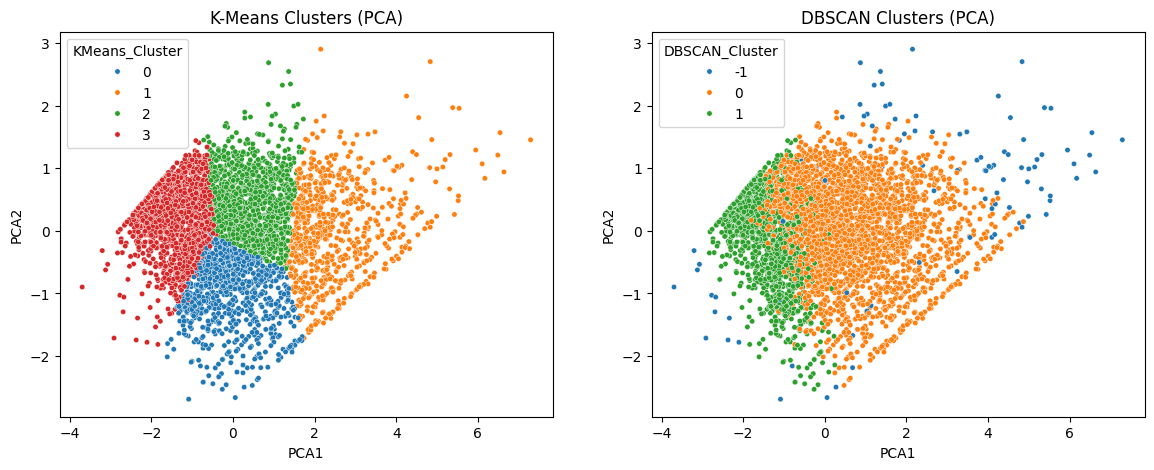

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x='PCA1', y='PCA2', hue='KMeans_Cluster', data=rfm, palette='tab10', s=15, ax=axes[0])
axes[0].set_title("K-Means Clusters (PCA)")

sns.scatterplot(x='PCA1', y='PCA2', hue='DBSCAN_Cluster', data=rfm, palette='tab10', s=15, ax=axes[1])
axes[1].set_title("DBSCAN Clusters (PCA)")

plt.show()


In [15]:
sample_idx = rfm.sample(n=min(3000, len(rfm)), random_state=42).index
sample_scaled = rfm_scaled.loc[sample_idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_result = tsne.fit_transform(sample_scaled)

tsne_df = pd.DataFrame(tsne_result, index=sample_idx, columns=['TSNE1', 'TSNE2'])
tsne_df['KMeans_Cluster'] = rfm.loc[sample_idx, 'KMeans_Cluster']
tsne_df['DBSCAN_Cluster'] = rfm.loc[sample_idx, 'DBSCAN_Cluster']
tsne_df.head()


,TSNE1,TSNE2,KMeans_Cluster,DBSCAN_Cluster
CustomerID,,,,
17785.0,-30.054470,-36.265774,3,1
14320.0,-18.467106,40.908226,3,0
15977.0,-1.058845,12.131432,0,0
12364.0,21.964294,-7.757188,0,0
14566.0,-42.168396,16.112284,3,1


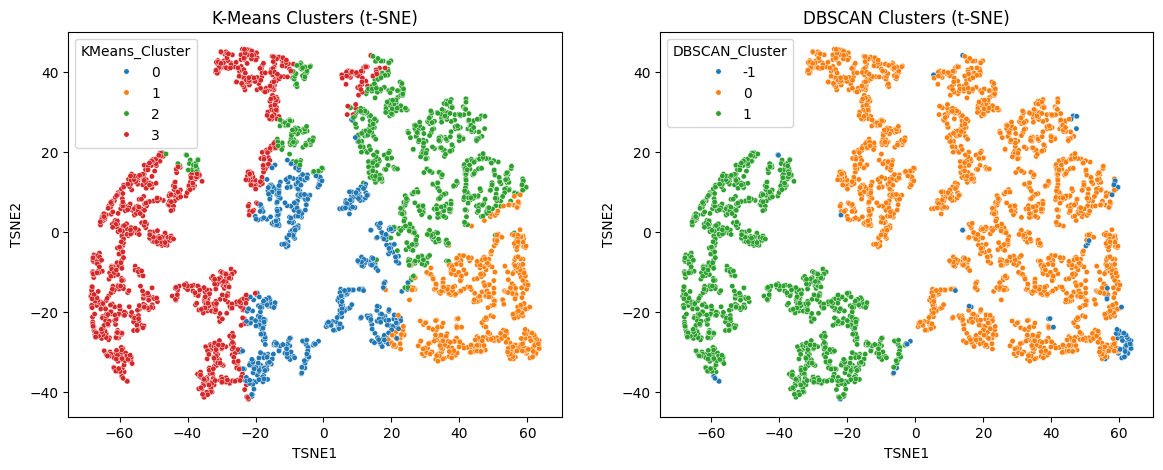

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x='TSNE1', y='TSNE2', hue='KMeans_Cluster', data=tsne_df, palette='tab10', s=15, ax=axes[0])
axes[0].set_title("K-Means Clusters (t-SNE)")

sns.scatterplot(x='TSNE1', y='TSNE2', hue='DBSCAN_Cluster', data=tsne_df, palette='tab10', s=15, ax=axes[1])
axes[1].set_title("DBSCAN Clusters (t-SNE)")

plt.show()


In [17]:
profile = rfm.groupby('KMeans_Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'KMeans_Cluster': 'count'
}).rename(columns={'KMeans_Cluster': 'Customers'}).round(2)

profile


,Recency,Frequency,Monetary,Customers
KMeans_Cluster,,,,
0,18.12,2.15,551.82,837
1,12.13,13.71,8074.27,716
2,71.08,4.08,1802.83,1173
3,182.50,1.32,343.45,1612


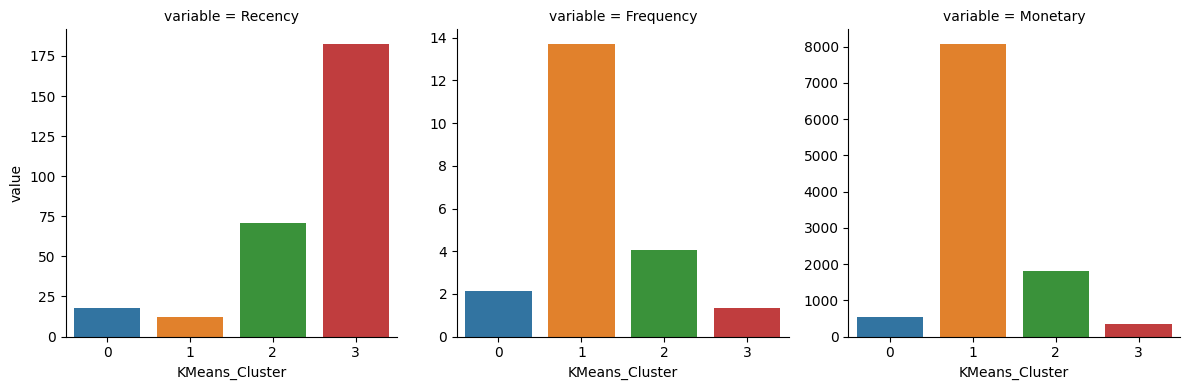

In [18]:
profile_melt = profile[['Recency', 'Frequency', 'Monetary']].reset_index().melt(id_vars='KMeans_Cluster')

g = sns.FacetGrid(profile_melt, col='variable', sharey=False, height=4)
g.map_dataframe(sns.barplot, x='KMeans_Cluster', y='value', palette='tab10')
plt.show()


In [19]:
avg_r = rfm['Recency'].mean()
avg_f = rfm['Frequency'].mean()
avg_m = rfm['Monetary'].mean()

def assign_persona(row):
    recent = row['Recency'] < avg_r
    frequent = row['Frequency'] > avg_f
    big_spender = row['Monetary'] > avg_m
    if recent and frequent and big_spender:
        return "Champions"
    elif recent and not frequent:
        return "New / Promising Customers"
    elif not recent and (frequent or big_spender):
        return "At-Risk Big Spenders"
    elif recent:
        return "Loyal Regulars"
    else:
        return "Lost / Hibernating Customers"

profile['Persona'] = profile.apply(assign_persona, axis=1)
profile


,Recency,Frequency,Monetary,Customers,Persona
KMeans_Cluster,,,,,
0,18.12,2.15,551.82,837,New / Promising Customers
1,12.13,13.71,8074.27,716,Champions
2,71.08,4.08,1802.83,1173,New / Promising Customers
3,182.50,1.32,343.45,1612,Lost / Hibernating Customers


In [20]:
marketing_actions = {
    "Champions": "Reward with VIP perks, early access to new products, and referral programs.",
    "Loyal Regulars": "Upsell and cross-sell, offer loyalty points and bundle deals.",
    "New / Promising Customers": "Send welcome series, onboarding offers, and encourage a second purchase.",
    "At-Risk Big Spenders": "Run win-back campaigns with personalized discounts and 'we miss you' emails.",
    "Lost / Hibernating Customers": "Low-cost reactivation emails or clearance offers; stop heavy spending on them."
}

profile['Marketing_Action'] = profile['Persona'].map(marketing_actions)

for cluster_id, row in profile.iterrows():
    print(f"Cluster {cluster_id} -> {row['Persona']}")
    print(f"  Customers: {int(row['Customers'])} | Recency: {row['Recency']} days | Frequency: {row['Frequency']} orders | Monetary: {row['Monetary']}")
    print(f"  Action: {row['Marketing_Action']}\n")


Cluster 0 -> New / Promising Customers
  Customers: 837 | Recency: 18.12 days | Frequency: 2.15 orders | Monetary: 551.82
  Action: Send welcome series, onboarding offers, and encourage a second purchase.

Cluster 1 -> Champions
  Customers: 716 | Recency: 12.13 days | Frequency: 13.71 orders | Monetary: 8074.27
  Action: Reward with VIP perks, early access to new products, and referral programs.

Cluster 2 -> New / Promising Customers
  Customers: 1173 | Recency: 71.08 days | Frequency: 4.08 orders | Monetary: 1802.83
  Action: Send welcome series, onboarding offers, and encourage a second purchase.

Cluster 3 -> Lost / Hibernating Customers
  Customers: 1612 | Recency: 182.5 days | Frequency: 1.32 orders | Monetary: 343.45
  Action: Low-cost reactivation emails or clearance offers; stop heavy spending on them.



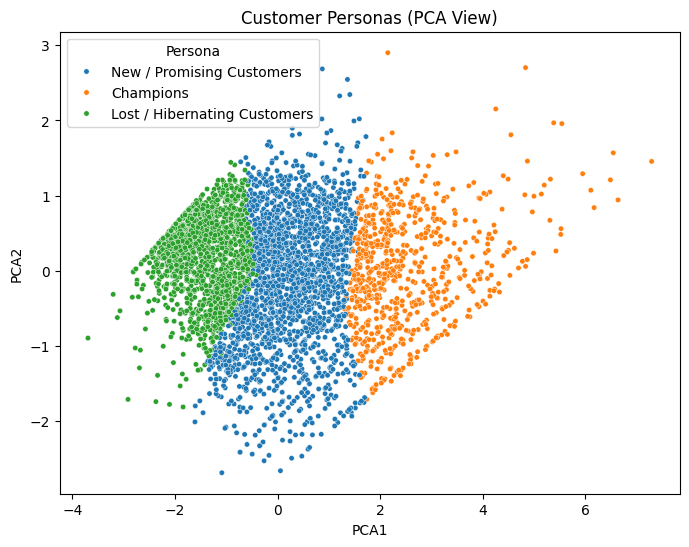

In [21]:
rfm['Persona'] = rfm['KMeans_Cluster'].map(profile['Persona'])

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PCA1', y='PCA2', hue='Persona', data=rfm, palette='tab10', s=15)
plt.title("Customer Personas (PCA View)")
plt.show()
